# Лабораторная работа: решение задачи классификации инструментами TensorFlow (табличные данные)

**Тема:** классификация состояний спутниковых подсистем (норма / неисправность) по телеметрии.
**Что изучаем:** слои `Dense`, `Dropout`, метрики `accuracy`, `precision`, `recall` (и немного `F1`, `ROC-AUC`, `PR-AUC`).
**Данные:** SMAP (TsFile) — телеметрия спутника NASA SMAP, 25 каналов, пометки аномалий по каждому моменту времени
([Hugging Face: THULab/SMAP](https://huggingface.co/datasets/THULab/SMAP), лицензия CC BY 4.0).

## Команда и распределение задач

Роли распределены по этапам пайплайна так, чтобы каждая участница отвечала за отдельный раздел.

| Участница | **Задача** | Раздел ноутбука |
|---|---|---|
| Толмачева | **Данные и лицензия** | 2 |
| Гарбузова | **Состав набора** | 3 |
| Бурова | **Предобработка** | 4 |
| Монахова | **Разбиение выборки** | 5 |
| Лукавенко | **Архитектура сети** | 6 |
| Гребенец | **Обучение** | 7 |
| Цыхоня | **Метрики** | 8 |
| Попова | **Графики** | 9 |
| Шмидт | **Разбор ошибок** | 10 |
| Ерцкина | **README и сдача** | 11 |

## Содержание
1. Теория
2. Данные и лицензия
3. Состав набора
4. Предобработка
5. Разбиение выборки
6. Архитектура сети
7. Обучение
8. Метрики
9. Графики
10. Разбор ошибок
11. README и сдача, выводы
12. Вопросы для самопроверки и глоссарий

## 1. Теория 

### 1.1. Что такое задача классификации?
**Классификация** — это когда компьютер должен отнести объект к одному из заранее известных классов.
Примеры из жизни: письмо «спам / не спам», фото «кошка / собака», анализ «здоров / болен».

У нас объект — **кусочек телеметрии спутника** (показания датчиков за короткий промежуток времени),
а классов два:

* **0 — норма** (подсистема работает штатно);
* **1 — неисправность / аномалия** (что-то пошло не так).

Когда классов два, задачу называют **бинарной классификацией**. Если бы классов было больше (норма, перегрев, сбой питания…),
она называлась бы **многоклассовой**.

### 1.2. Обучение с учителем: «учим по примерам с ответами»
Мы показываем модели много примеров, где **известен правильный ответ** (метка / label), и она подбирает свои внутренние числа так, чтобы
давать правильные ответы. Потом проверяем её на примерах, которых она ещё не видела.

* **Признаки (features, X)** — то, что мы подаём на вход: числа с датчиков.
* **Метка (label, y)** — правильный ответ: 0 или 1.
* **Модель** — «чёрный ящик» с настраиваемыми числами (**весами**), который превращает X в ответ.

### 1.3. Табличные данные
Таблица: **строка = один пример, столбец = один признак**. Нейросети для таблиц обычно состоят из полносвязных слоёв (`Dense`).
Наши данные — это временной ряд (измерения идут друг за другом), но мы превратим его в таблицу: вырежем окна по 50 отсчётов
и посчитаем для каждого окна статистики (среднее, разброс, минимум, максимум, изменение). Каждая строка новой таблицы — одно окно.

### 1.4. Нейрон и слой Dense — простыми словами
**Нейрон** — это маленькая формула: он берёт входные числа, умножает каждое на свой «вес», складывает, добавляет «смещение» (bias)
и пропускает результат через **функцию активации**:

$$ y = f\big(w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b\big) $$

**Слой Dense (полносвязный)** — это набор таких нейронов, где **каждый нейрон смотрит на все входы** предыдущего слоя.
Если на входе 125 чисел, а в слое 64 нейрона, то весов будет $125 \cdot 64$ плюс 64 смещения = **8 064 параметра**.
Именно эти числа и подбираются при обучении.

Аналогия: представьте жюри из 64 экспертов. Каждый смотрит на все 125 показателей, но придаёт разным показателям разную важность (веса).
Потом следующий слой — «жюри жюри», которое смотрит на мнения первого и выносит итоговый вердикт.

### 1.5. Функции активации
Без активации сколько слоёв ни складывай, получится одна большая линейная формула — это слишком просто.
Активация добавляет «изгиб» и позволяет сети ловить сложные зависимости.

| Активация | Формула | Где используем | Простыми словами |
|---|---|---|---|
| **ReLU** | $\max(0, x)$ | скрытые слои | «Отрицательное — обнули, положительное — оставь». Быстрая и надёжная. |
| **Sigmoid** | $\frac{1}{1+e^{-x}}$ | выход бинарной классификации | Превращает любое число в число от 0 до 1 — «вероятность аномалии». |
| **Softmax** | — | выход многоклассовой задачи | Раздаёт вероятности по нескольким классам так, что сумма = 1. |

### 1.5.1. Как сеть учится: функция потерь, градиентный спуск, Adam
* **Функция потерь (loss)** — число, которое показывает, насколько сеть ошибается. Для бинарной классификации используют
  **бинарную кросс-энтропию**: она сильно штрафует уверенные, но неправильные ответы
  (сказала «99% норма», а на деле аномалия — штраф огромный).
* **Градиентный спуск** — как идти с завязанными глазами вниз по склону: ощупываешь, куда уклон, делаешь маленький шаг вниз.
  Здесь «склон» — это loss, «шаг» — небольшое изменение весов.
* **Learning rate (скорость обучения)** — длина шага. Слишком большой — перепрыгиваем минимум, слишком маленький — учимся вечно.
* **Adam** — популярный «умный» вариант градиентного спуска, сам подстраивает шаг для каждого веса.
* **Эпоха** — один полный проход по всем обучающим примерам. **Batch (пакет)** — порция примеров (например, 256),
  после которой делается один шаг обновления весов.

### 1.6. Dropout — «случайно выключаем нейроны»
**Проблема — переобучение (overfitting):** сеть слишком хорошо запоминает обучающие примеры (вместе с шумом) и плохо работает на новых.
Это как зубрить ответы билетов вместо понимания предмета.

**Dropout** во время обучения на каждом шаге **случайно «выключает» долю нейронов** (например, 30%). Сеть не может полагаться
на отдельных «любимчиков» и вынуждена учить устойчивые, распределённые закономерности.
Аналогия: команда, где на каждой тренировке случайные игроки сидят на скамейке, — в итоге играть умеют все.

Важно: **при предсказании (inference) Dropout автоматически отключается** — работает вся сеть. Keras делает это сам.
Параметр `rate=0.3` означает «выключаем 30% нейронов».

### 1.7. Подготовка данных: масштабирование
Датчики измеряют в разных единицах: температура в сотнях, ток в долях. Сеть чувствительна к масштабу, поэтому приводим признаки
к сопоставимому виду, например **стандартизацией**: $z = (x - \mu)/\sigma$ (среднее 0, разброс 1).

> **Утечка данных (data leakage)** — самая частая ошибка. Нельзя считать $\mu$ и $\sigma$ по **всем** данным, включая тестовые:
> тогда информация о «будущем» просочится в обучение, и результат будет завышен. Масштабатор «обучаем» **только на обучающей части**,
> а к остальным частям только применяем.

### 1.8. Разбиение выборки: train / validation / test
* **Train (обучающая)** — на ней сеть учится.
* **Validation (валидационная)** — на ней мы подбираем настройки (порог, момент остановки обучения). Сеть на ней **не учится**.
* **Test (тестовая)** — финальный экзамен, на который мы смотрим **один раз** в конце.

Для временных рядов **нельзя перемешивать** примеры случайно: соседние окна почти одинаковые, и копии одного и того же события окажутся
и в обучении, и в тесте — сеть «подсмотрит». Поэтому режем **по времени**: начало ряда — train, середина — validation, конец — test.

### 1.9. Дисбаланс классов
Аномалий в телеметрии **намного меньше**, чем нормы (в SMAP порядка 13% строк размечены как аномальные). Если ничего не делать, сеть быстро
понимает: «выгодно всегда отвечать *норма*» — и получает высокую accuracy, не умея находить ни одной неисправности.
Лекарства:
* **веса классов** (`class_weight`): ошибка на редком классе штрафуется сильнее;
* подбор **порога** принятия решения (не обязательно 0.5);
* правильные **метрики** (см. ниже).

### 1.10. Метрики классификации
Любой ответ классификатора попадает в одну из четырёх клеток (**матрица ошибок, confusion matrix**). Считаем «положительным» классом аномалию:

|  | Модель: «аномалия» | Модель: «норма» |
|---|---|---|
| **На деле аномалия** | **TP** — нашли | **FN** — пропустили (опасно!) |
| **На деле норма** | **FP** — ложная тревога | **TN** — верно «норма» |

* **Accuracy (точность в целом)** = $\dfrac{TP+TN}{TP+TN+FP+FN}$ — доля правильных ответов.
  *Подвох:* при 87% нормы ответ «всегда норма» даёт accuracy 87% — и абсолютно бесполезен.
* **Precision (точность по классу)** = $\dfrac{TP}{TP+FP}$ — «когда модель кричит *тревога*, как часто она права?»
  Низкая precision = куча ложных тревог, операторам надоедает реагировать.
* **Recall (полнота, чувствительность)** = $\dfrac{TP}{TP+FN}$ — «какую долю реальных неисправностей мы поймали?»
  Низкий recall = пропускаем настоящие поломки. Для спутника это обычно самое страшное.
* **F1** = $\dfrac{2\cdot P\cdot R}{P+R}$ — одно число, «компромисс» precision и recall.
* **ROC-AUC** и **PR-AUC** — площади под кривыми, не зависят от выбранного порога. Для редких аномалий PR-AUC информативнее.

**Аналогия с рыбалкой.** Сеть — это невод. Precision — «какая часть улова — нужная рыба, а не мусор». Recall — «какую долю всей нужной рыбы из озера мы вытащили».
Мелкая сетка ловит почти всю рыбу (высокий recall), но и кучу мусора (низкая precision). Крупная ячейка — наоборот.
**Порог** — это размер ячейки; мы его настраиваем.

### 1.11. Порог принятия решения
Сеть на выходе отдаёт число от 0 до 1 (вероятность аномалии). Мы сами решаем: «если ≥ 0.5 — аномалия». Но 0.5 — просто привычка.
Снижая порог, мы повышаем recall (ловим больше), но платим precision (больше ложных тревог). Порог подбирают **на валидации**.

### 1.12. Про сами данные SMAP
SMAP (Soil Moisture Active Passive) — спутник NASA для измерения влажности почвы. Набор содержит 25 каналов телеметрии
(часть — аналоговые показания, часть — бинарные «командные» каналы). Исходный набор — из Time-Series-Library (Tsinghua University),
здесь он упакован в формат **Apache TsFile** (специальный формат хранения временных рядов).
Устройство набора: **train** — 135 183 строки, все нормальные (меток нет, все 0); **test** — 427 617 строк с метками 0/1.

Из этого следуют два важных решения для нашей работы:
1. Меток **две** (0/1), поэтому ставим задачу как **бинарную «норма / аномалия»**. Выбор фиксируем в README.
2. Файл train содержит **один класс**, учить классификатор на нём нельзя. Поэтому учим, валидируем и тестируем модель на **файле test**,
   разрезав его по времени. Train-файл используем только для знакомства с данными (и как «чистый» образец нормы).

### Подготовка окружения
Для запуска нужны только этот ноутбук и файлы датасета, дополнительные скрипты не требуются.

1. Файлы `SMAP_train.tsfile` и `SMAP_test.tsfile` должны лежать в папке `data/raw/` рядом с ноутбуком (в репозитории они уже есть).
2. Jupyter запускают из папки с ноутбуком: рабочая папка определяется через `Path.cwd()`.
3. Если каких-то библиотек не хватает:
```
pip install tensorflow tsfile numpy pandas scikit-learn matplotlib
```
Проверено на Python 3.12.10 и TensorFlow 2.21.0.

При первом запуске автоматически создаётся кэш `data/cache/smap.npz` (ускоряет повторные запуски). В репозиторий его добавлять не нужно.

In [ ]:
import os, random, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, precision_recall_curve, roc_curve,
                             roc_auc_score, average_precision_score, classification_report)

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

# ---- воспроизводимость: фиксируем случайность
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- настройки
ROOT      = Path.cwd()                 # ноутбук лежит в папке lab02_TensorFlow
DATA_DIR  = ROOT / "data"
RAW_DIR   = DATA_DIR / "raw"           # сюда кладём файлы датасета (.tsfile)
CACHE_DIR = DATA_DIR / "cache"         # быстрый кэш
CACHE_DIR.mkdir(parents=True, exist_ok=True)

WINDOW  = 50                           # длина окна (отсчётов)
STRIDE  = 10                           # шаг окна
SPLIT   = (0.6, 0.2, 0.2)              # доли train / val / test по времени
BATCH   = 256
EPOCHS  = 40

print("TensorFlow:", tf.__version__)
print("Рабочая папка:", ROOT)

TensorFlow: 2.21.0
Рабочая папка: d:\_учебное\Нейрокомпы Доррер\lab02_TensorFlow


---
## 2. Данные и лицензия
**Ответственная: Толмачева**.

### Что нужно сделать в этом разделе
1. Загрузить файлы набора и убедиться, что они читаются.
2. Зафиксировать источник, авторов и лицензию.
3. Объяснить, что можно и что нельзя делать с данными.

### Теория: что такое лицензия на данные
Лицензия — это «правила пользования». **CC BY 4.0** (Creative Commons Attribution) разрешает:
* копировать и распространять данные;
* изменять и использовать в своих проектах, в том числе в учебных и коммерческих;

при одном условии — **указать автора (attribution)**, дать ссылку на лицензию и отметить, если вы вносили изменения
(мы, например, режем ряд на окна).

| Пункт | Значение |
|---|---|
| Набор | SMAP (TsFile) |
| Публикация | [huggingface.co/datasets/THULab/SMAP](https://huggingface.co/datasets/THULab/SMAP), организация THULab |
| Оригинал | подмножество `SMAP` из [thuml/Time-Series-Library](https://huggingface.co/datasets/thuml/Time-Series-Library) (Tsinghua University) |
| Статья | Deep Time Series Models: A Comprehensive Survey and Benchmark, [arXiv:2407.13278](https://arxiv.org/abs/2407.13278) |
| Лицензия | CC BY 4.0 |
| Размер | ≈ 1.13 МБ (2 файла) |
| Наши изменения | оконные признаки, стандартизация, разбиение по времени |

Формат **TsFile** — открытый колоночный формат Apache для временных рядов. Читается библиотекой `tsfile` для Python.

In [2]:
def read_tsfile(path: Path) -> pd.DataFrame:
    """Читает .tsfile в DataFrame. Если API библиотеки отличается, печатает подсказку."""
    try:
        import tsfile
    except ImportError as e:
        raise ImportError("Не установлена библиотека tsfile: pip install tsfile") from e
    try:
        from tsfile import to_dataframe
        df = to_dataframe(str(path))
        if len(df) > 0:
            return df
        raise ValueError("to_dataframe вернул пустую таблицу")
    except Exception as e:
        print("Не удалось прочитать через to_dataframe:", repr(e))
        print("Доступные объекты в tsfile:", [n for n in dir(tsfile) if not n.startswith('_')])
        raise


def tidy(df: pd.DataFrame):
    """Приводит таблицу к виду: X (n x 25, float32), y (n,), имена каналов."""
    df = df.copy()
    low = {c: str(c).lower() for c in df.columns}
    time_cols  = [c for c in df.columns if low[c] in ("time", "timestamp")]
    label_cols = [c for c in df.columns if low[c].split(".")[-1] == "label"]
    df = df.drop(columns=time_cols)
    y = df[label_cols[0]].to_numpy().astype(int) if label_cols else None
    feat = df.drop(columns=label_cols).select_dtypes("number")
    return feat.to_numpy(dtype=np.float32), y, list(feat.columns)


def load_smap():
    """Порядок: кэш -> .tsfile -> запасной вариант .npy (из Time-Series-Library)."""
    cache = CACHE_DIR / "smap.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)
        return z["Xtr"], z["ytr"], z["Xte"], z["yte"], list(z["names"])

    f_tr, f_te = RAW_DIR / "SMAP_train.tsfile", RAW_DIR / "SMAP_test.tsfile"
    if not (f_tr.exists() and f_te.exists()):
        found = list(RAW_DIR.rglob("*.tsfile"))
        tr = [p for p in found if "train" in p.name.lower()]
        te = [p for p in found if "test" in p.name.lower()]
        if tr and te:
            f_tr, f_te = tr[0], te[0]

    if f_tr.exists() and f_te.exists():
        Xtr, ytr, names = tidy(read_tsfile(f_tr))
        Xte, yte, _     = tidy(read_tsfile(f_te))
    elif (RAW_DIR / "SMAP_test.npy").exists():       # запасной путь
        Xtr = np.load(RAW_DIR / "SMAP_train.npy").astype(np.float32)
        Xte = np.load(RAW_DIR / "SMAP_test.npy").astype(np.float32)
        yte = np.load(RAW_DIR / "SMAP_test_label.npy").astype(int)
        ytr = np.zeros(len(Xtr), dtype=int)
        names = [f"ch_{i:02d}" for i in range(Xtr.shape[1])]
    else:
        raise FileNotFoundError("Нет данных в data/raw. Положите туда SMAP_train.tsfile и SMAP_test.tsfile.")

    np.savez_compressed(cache, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, names=np.array(names))
    return Xtr, ytr, Xte, yte, names


Xtr_raw, ytr_raw, Xte_raw, yte_raw, CH_NAMES = load_smap()
print("train:", Xtr_raw.shape, "| test:", Xte_raw.shape, "| каналов:", len(CH_NAMES))

train: (135183, 25) | test: (427617, 25) | каналов: 25


**Проверка (для Толмачевой):** должно получиться `train: (135183, 25)`, `test: (427617, 25)`.
Если числа другие или чтение падает, нужно записать в README, какую версию `tsfile` вы ставили, и приложить текст ошибки.
Запасной путь: положить в `data/raw/` файлы `SMAP_train.npy`, `SMAP_test.npy`, `SMAP_test_label.npy` из Time-Series-Library.

---
## 3. Состав набора
**Ответственная: Гарбузова**.

### Что нужно сделать
1. Описать размеры, каналы, пропуски.
2. Посчитать баланс классов и найти аномальные участки.
3. **Выбрать постановку задачи** (бинарная или все классы) до обучения и записать решение.

### Теория
Прежде чем учить модель, надо «познакомиться с данными»: сколько их, какие бывают значения, нет ли дыр, как распределены классы.
Это называется **разведочный анализ (EDA)**. Он спасает от глупых ошибок: например, от обучения на файле, где только один класс.

In [3]:
def runs(y):
    """Начала и концы подряд идущих участков, где y == 1."""
    y = np.asarray(y).astype(int)
    d = np.diff(np.r_[0, y, 0])
    return np.where(d == 1)[0], np.where(d == -1)[0]

print("Пропуски  train/test:", int(np.isnan(Xtr_raw).sum()), "/", int(np.isnan(Xte_raw).sum()))
print("Уникальные метки в train:", np.unique(ytr_raw), "| в test:", np.unique(yte_raw))

n1 = int(yte_raw.sum()); n = len(yte_raw)
print(f"Test: норма = {n-n1} ({100*(n-n1)/n:.1f}%), аномалия = {n1} ({100*n1/n:.1f}%)")

s, e = runs(yte_raw)
lens = e - s
print(f"Аномальных участков: {len(s)}; длина (мин/медиана/макс): {lens.min()} / {int(np.median(lens))} / {lens.max()}")

stats = pd.DataFrame({
    "min": Xte_raw.min(0), "mean": Xte_raw.mean(0), "max": Xte_raw.max(0), "std": Xte_raw.std(0),
    "уник.значений": [len(np.unique(Xte_raw[:20000, i])) for i in range(Xte_raw.shape[1])],
}, index=CH_NAMES)
stats["бинарный?"] = stats["уник.значений"] <= 2
stats.round(3)

Пропуски  train/test: 0 / 0
Уникальные метки в train: [0] | в test: [0 1]
Test: норма = 372921 (87.2%), аномалия = 54696 (12.8%)
Аномальных участков: 67; длина (мин/медиана/макс): 31 / 131 / 4218


,min,mean,max,std,уник.значений,бинарный?
channel_0,-1.0,-0.180,1.0,0.775,83,False
channel_1,0.0,0.019,1.0,0.137,2,True
channel_2,0.0,0.003,1.0,0.059,2,True
channel_3,0.0,0.015,1.0,0.123,2,True
channel_4,0.0,0.000,1.0,0.018,2,True
channel_5,0.0,0.090,1.0,0.286,2,True
channel_6,0.0,0.069,1.0,0.253,2,True
channel_7,0.0,0.001,1.0,0.026,2,True
channel_8,0.0,0.000,1.0,0.014,2,True
channel_9,0.0,0.000,1.0,0.018,2,True


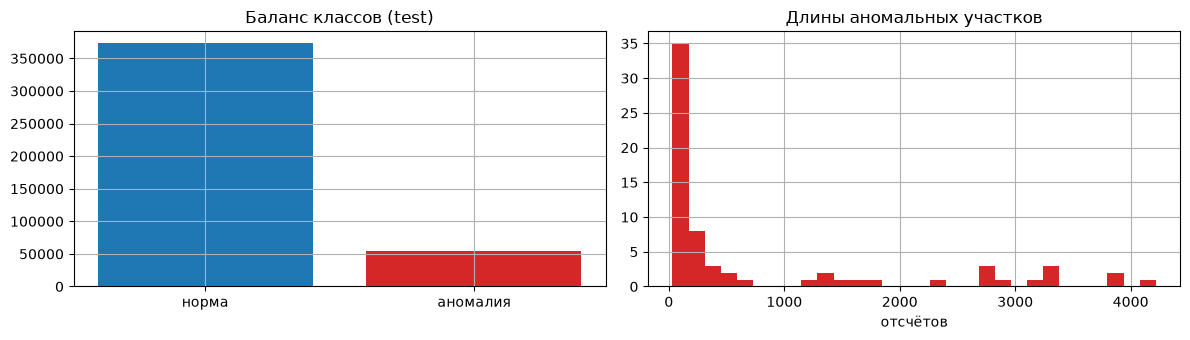

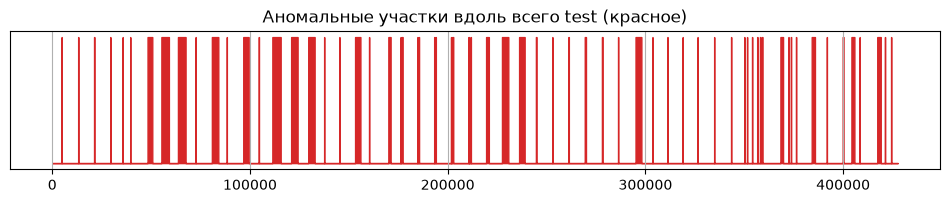

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(["норма", "аномалия"], [n - n1, n1], color=["tab:blue", "tab:red"])
ax[0].set_title("Баланс классов (test)")
ax[1].hist(lens, bins=30, color="tab:red"); ax[1].set_title("Длины аномальных участков"); ax[1].set_xlabel("отсчётов")
plt.tight_layout(); plt.show()

# Положение аномалий во времени: где они расположены в test?
fig, ax = plt.subplots(figsize=(12, 1.8))
ax.fill_between(np.arange(n), yte_raw, step="mid", color="tab:red")
ax.set_yticks([]); ax.set_title("Аномальные участки вдоль всего test (красное)"); plt.show()

### Решение по постановке задачи (зафиксировано до обучения)
Меток **две** (0 — норма, 1 — аномалия), других классов в наборе нет. Поэтому выбираем **бинарную постановку «норма / аномалия»**.
Файл train состоит только из нормы, поэтому для обучения классификатора не годится; модель учится на первой по времени части файла test
(см. раздел 5).

**Вывод по составу набора:** в test аномальны 12,8% отсчётов, они образуют 67 участков длиной от 31 до 4 218 отсчётов (медиана — 131). Большинство каналов бинарные или постоянные, поэтому важно анализировать распределение по времени и не полагаться только на accuracy.

---
## 4. Предобработка
**Ответственная: Бурова**.

### Что нужно сделать
1. Обработать пропуски и константные каналы (если есть).
2. Превратить ряд в таблицу: окна → признаки.
3. Стандартизировать признаки **без утечки** (масштабатор учится только на train-части).

### Теория
**Почему не подавать строки по одной?** Одно мгновение телеметрии часто не показывает проблему: неисправность проявляется в *динамике*
(рост, скачки, дрожание). Поэтому берём **окно** из 50 подряд идущих отсчётов и описываем его несколькими числами по каждому каналу:

| Признак окна | Что показывает |
|---|---|
| среднее (mean) | на каком уровне держится сигнал |
| стандартное отклонение (std) | насколько «трясёт» |
| минимум и максимум | были ли провалы или выбросы |
| последнее − первое (trend) | куда движется сигнал |

25 каналов × 5 признаков = **125 признаков** на одно окно.

**Метка окна:** 1, если **хотя бы одна** точка внутри окна размечена как аномалия. Это осторожный подход: лучше лишний раз насторожиться,
чем пропустить.

**Шаг окна (stride):** окна идут не вплотную, а с шагом 10 — так примеров больше, но они перекрываются.
Из-за перекрытия окна-соседи очень похожи — ещё одна причина резать выборку по времени, а не случайно.

In [5]:
# --- 1) константные каналы в train-части мы определим ПОСЛЕ разбиения (раздел 5), чтобы не было утечки
# --- 2) функция превращения ряда в таблицу признаков
STATS = ["mean", "std", "min", "max", "trend"]

def make_windows(X, y, window=WINDOW, stride=STRIDE, chunk=4000):
    """X: (n, ch) -> признаки (n_окон, ch*5), метки окон, индекс начала каждого окна."""
    starts = np.arange(0, len(X) - window + 1, stride)
    feats, labels = [], []
    for i in range(0, len(starts), chunk):
        st = starts[i:i + chunk]
        idx = st[:, None] + np.arange(window)[None, :]
        W = X[idx]                                           # (chunk, window, ch)
        feats.append(np.concatenate([W.mean(1), W.std(1), W.min(1), W.max(1), W[:, -1] - W[:, 0]], axis=1))
        labels.append(y[idx].max(1))
    return np.concatenate(feats).astype(np.float32), np.concatenate(labels).astype(int), starts

FEAT_NAMES = [f"{s}_{c}" for s in STATS for c in CH_NAMES]
print("Признаков на окно:", len(FEAT_NAMES))

# --- мини-проверка на игрушечных данных, чтобы убедиться, что функция работает правильно
toy_X = np.arange(10, dtype=np.float32).reshape(-1, 1).repeat(2, axis=1)
toy_y = np.array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0])
f, l, st = make_windows(toy_X, toy_y, window=4, stride=2)
print("начала окон:", st, "| метки окон:", l)       # окна [0:4],[2:6],[4:8],[6:10] -> 0,1,1,0

Признаков на окно: 125
начала окон: [0 2 4 6] | метки окон: [0 1 1 0]


Стандартизацию (`StandardScaler`) применим в разделе 5 сразу после разбиения: она должна «знать» только обучающую часть.
**Вывод по предобработке:** пропусков нет, в train-части не обнаружены константные признаки. Окна длиной 50 отсчётов с шагом 10 сохраняют локальный контекст; пять статистик на канал формируют 125 признаков. Эти решения описаны в README.

---
## 5. Разбиение выборки
**Ответственная: Монахова**.

### Что нужно сделать
1. Разрезать test-файл **по времени** на train / val / test.
2. Проверить, что в каждой части есть оба класса.
3. Обучить стандартизатор только на train; посчитать веса классов.

### Теория
Представьте, что вы готовите студента к экзамену. Если вы заранее покажете ему экзаменационные билеты (утечка), оценка за экзамен
ничего не скажет о его знаниях. Тест должен быть «неизвестным будущим». Для рядов «будущее» — это **более поздние по времени участки**.

Дополнительные меры:
* **Окна нарезаем после разбиения** — тогда ни одно окно не пересекает границу частей.
* **Стандартизатор обучаем на train** и применяем к val/test.
* **Веса классов** считаем только по train: $w_c = \dfrac{N}{2 N_c}$ — редкий класс получает больший вес.

In [6]:
X_all, y_all = Xte_raw, yte_raw                      # учимся на файле test (в train-файле один класс)
n_all = len(X_all)
i1 = int(n_all * SPLIT[0]); i2 = int(n_all * (SPLIT[0] + SPLIT[1]))
segments = {"train": (0, i1), "val": (i1, i2), "test": (i2, n_all)}

# масштабатор учим ТОЛЬКО на сырых строках train-части
scaler = StandardScaler().fit(X_all[:i1])
const_ch = np.where(scaler.scale_ < 1e-8)[0]
scaler.scale_[const_ch] = 1.0                         # константный канал: не делим на ноль
print("Константных каналов в train-части:", [CH_NAMES[i] for i in const_ch])

data = {}
for name, (a, b) in segments.items():
    Xs = scaler.transform(X_all[a:b]).astype(np.float32)
    F, L, st = make_windows(Xs, y_all[a:b])
    data[name] = dict(X=F, y=L, starts=st + a)        # starts в координатах всего test-файла
    print(f"{name:5s}: строк {b-a:7d} | окон {len(L):6d} | аномальных окон {int(L.sum()):5d} ({100*L.mean():.1f}%)")

X_tr, y_tr = data["train"]["X"], data["train"]["y"]
X_va, y_va = data["val"]["X"],   data["val"]["y"]
X_te, y_te = data["test"]["X"],  data["test"]["y"]

for k in ("train", "val", "test"):
    assert 0 < data[k]["y"].sum() < len(data[k]["y"]), (
        f"В части {k} только один класс. Измените SPLIT в настройках (например, (0.5, 0.25, 0.25)).")

# окончательное масштабирование признаков окон (разный масштаб у std и mean и т.д.)
feat_scaler = StandardScaler().fit(X_tr)
fs = feat_scaler.scale_.copy(); fs[fs < 1e-8] = 1.0; feat_scaler.scale_ = fs
X_tr, X_va, X_te = [feat_scaler.transform(a).astype(np.float32) for a in (X_tr, X_va, X_te)]

n0, n1_ = (y_tr == 0).sum(), (y_tr == 1).sum()
class_weight = {0: len(y_tr) / (2 * n0), 1: len(y_tr) / (2 * n1_)}
print("Веса классов:", {k: round(v, 3) for k, v in class_weight.items()})

Константных каналов в train-части: []
train: строк  256570 | окон  25653 | аномальных окон  4338 (16.9%)
val  : строк   85523 | окон   8548 | аномальных окон   508 (5.9%)
test : строк   85524 | окон   8548 | аномальных окон   952 (11.1%)
Веса классов: {0: np.float64(0.602), 1: np.float64(2.957)}


**Вывод по разбиению:** части выделены хронологически в пропорции 60/20/20; доли аномальных окон — 16,9%, 5,9% и 11,1%. Случайное разбиение могло бы поместить перекрывающиеся окна в разные выборки и завысить оценку. Эти результаты приведены в README.

---
## 6. Архитектура сети
**Ответственная: Лукавенко**.

### Что нужно сделать
1. Собрать модель из слоёв `Dense` и `Dropout`.
2. Объяснить назначение каждого слоя и посчитать число параметров.
3. Скомпилировать модель с метриками accuracy, precision, recall (+ AUC).

### Теория
Наша сеть — «конвейер» из слоёв:

```
вход (125 чисел) → Dense(64, ReLU) → Dropout(0.3) → Dense(32, ReLU) → Dropout(0.3) → Dense(1, Sigmoid) → вероятность аномалии
```

* **Input** — «приёмная»: принимает 125 признаков окна.
* **Dense(64, ReLU)** — 64 «эксперта» ищут комбинации признаков (например, «рост среднего при одновременном росте разброса»).
* **Dropout(0.3)** — на обучении случайно отключает 30% нейронов, борется с переобучением.
* **Dense(32, ReLU)** — «эксперты второго уровня» комбинируют выводы первого.
* **Dense(1, Sigmoid)** — выход: число от 0 до 1 («вероятность неисправности»).

**Откуда параметры?** У `Dense(n_in → n_out)` их $n_{in}\cdot n_{out} + n_{out}$.
Первый слой: $125\cdot64+64 = 8064$; второй: $64\cdot32+32 = 2080$; выход: $32\cdot1+1 = 33$. Итого **10 177**. `Dropout` параметров не имеет.

**Почему так мало слоёв?** Для табличных данных небольшая сеть обычно работает не хуже большой, учится быстро и меньше переобучается.
Глубину и ширину можно менять и сравнивать — это хорошее дополнительное задание.

**Метрики при компиляции:** `Precision`, `Recall` и `AUC` в Keras по умолчанию считаются для порога 0.5 (кроме AUC, он считается по всем порогам).

In [7]:
def build_model(n_features, units=(64, 32), dropout=0.3, lr=1e-3):
    inputs = keras.Input(shape=(n_features,), name="window_features")
    x = inputs
    for i, u in enumerate(units):
        x = layers.Dense(u, activation="relu", name=f"dense_{i+1}")(x)
        if dropout > 0:
            x = layers.Dropout(dropout, name=f"dropout_{i+1}")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="p_anomaly")(x)
    model = keras.Model(inputs, outputs, name=f"smap_mlp_do{dropout}")
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy",
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.AUC(name="auc"),
                 keras.metrics.AUC(name="pr_auc", curve="PR")],
    )
    return model

model = build_model(X_tr.shape[1])
model.summary()

Model: "smap_mlp_do0.3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ window_features (InputLayer)    │ (None, 125)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_anomaly (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,177 (39.75 KB)

 Trainable params: 10,177 (39.75 KB)

 Non-trainable params: 0 (0.00 B)

**Вывод по архитектуре:** расчёт совпал с `summary()` — в сети 10 177 параметров. Таблица слоёв и число параметров приведены в README.

---
## 7. Обучение
**Ответственная: Гребенец**.

### Что нужно сделать
1. Обучить модель с весами классов и ранней остановкой.
2. Сравнить сеть **с Dropout и без него**.
3. Записать выбранные гиперпараметры и время обучения.

### Теория
* **EarlyStopping (ранняя остановка).** Следим за качеством на валидации. Если несколько эпох подряд оно не улучшается — прекращаем
  и возвращаем лучшие веса. Это как перестать зубрить, когда на пробных тестах оценки уже не растут.
* **ReduceLROnPlateau.** Если застряли, уменьшаем шаг обучения — аккуратнее подбираемся к минимуму.
* **class_weight.** Ошибка на редком классе (аномалия) «весит» больше.
* **Как читать кривые обучения.**
  * train-loss падает, val-loss падает — всё хорошо.
  * train-loss падает, val-loss растёт — **переобучение**.
  * обе кривые высокие — **недообучение**, сеть слишком простая или мало эпох.

In [8]:
import time

def train(dropout, units=(64, 32), lr=1e-3, verbose=0):
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    m = build_model(X_tr.shape[1], units=units, dropout=dropout, lr=lr)
    cbs = [
        keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    h = m.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS, batch_size=BATCH,
              class_weight=class_weight, callbacks=cbs, verbose=verbose)
    print(f"dropout={dropout}: {len(h.history['loss'])} эпох, {time.time()-t0:.0f} c, "
          f"лучший val_pr_auc={max(h.history['val_pr_auc']):.3f}")
    return m, h

model_nodrop, hist_nodrop = train(dropout=0.0)
model_drop,   hist_drop   = train(dropout=0.3)


dropout=0.0: 11 эпох, 7 c, лучший val_pr_auc=0.157
dropout=0.3: 12 эпох, 7 c, лучший val_pr_auc=0.184


In [9]:
def val_scores(m, name):
    p = m.predict(X_va, batch_size=1024, verbose=0).ravel()
    pred = (p >= 0.5).astype(int)
    return {"модель": name,
            "accuracy":  accuracy_score(y_va, pred),
            "precision": precision_score(y_va, pred, zero_division=0),
            "recall":    recall_score(y_va, pred, zero_division=0),
            "F1":        f1_score(y_va, pred, zero_division=0),
            "PR-AUC":    average_precision_score(y_va, p)}

cmp = pd.DataFrame([val_scores(model_nodrop, "без Dropout"), val_scores(model_drop, "Dropout 0.3")]).set_index("модель")
cmp.round(3)

,accuracy,precision,recall,F1,PR-AUC
модель,,,,,
без Dropout,0.354,0.075,0.874,0.139,0.158
Dropout 0.3,0.383,0.078,0.864,0.143,0.189


Выбираем модель с лучшим значением на **валидации** (не на тесте!). Тест остаётся неприкосновенным до раздела 8.
**Вывод по обучению:** Dropout 0.3 дал небольшое преимущество по validation PR-AUC (0,189 против 0,158) и F1 при пороге 0,5 (0,143 против 0,139); обучение остановилось через 12 эпох против 11 без Dropout. Веса классов использовались в обоих вариантах.

In [10]:
# выбираем лучшую по PR-AUC на валидации
best_name = cmp["PR-AUC"].idxmax()
model, history = (model_drop, hist_drop) if best_name == "Dropout 0.3" else (model_nodrop, hist_nodrop)
print("Выбрана модель:", best_name)

Выбрана модель: Dropout 0.3


---
## 8. Метрики
**Ответственная: Цыхоня**.

### Что нужно сделать
1. Посчитать accuracy, precision, recall, F1 на тесте.
2. Сравнить с наивным базовым ответом «всегда норма».
3. Подобрать порог на валидации и оценить, как он меняет баланс precision/recall.

### Теория
Вспомните рыбалку из теории: порог — это размер ячейки невода. Мы выбираем порог **на валидации** (максимум F1), а затем один раз оцениваем
на тесте. Если подбирать порог на тесте, мы «подгоним» его под экзамен — это снова утечка.

**Базовая модель (baseline)** — самый глупый осмысленный ответ. Здесь это «всегда норма». Если наша сеть не лучше baseline по recall и F1,
она бесполезна, как бы красиво ни выглядела accuracy.

In [11]:
p_va = model.predict(X_va, batch_size=1024, verbose=0).ravel()
p_te = model.predict(X_te, batch_size=1024, verbose=0).ravel()

# порог по максимуму F1 на ВАЛИДАЦИИ
prec, rec, thr = precision_recall_curve(y_va, p_va)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
THR = float(thr[np.argmax(f1s)])
print(f"Подобранный порог: {THR:.3f}")

def report(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0)}

baseline = report(y_te, np.zeros_like(p_te), 0.5)
rows = {"baseline: всегда «норма»": baseline,
        "сеть, порог 0.5": report(y_te, p_te, 0.5),
        f"сеть, порог {THR:.2f} (по val)": report(y_te, p_te, THR)}
metrics_table = pd.DataFrame(rows).T
metrics_table["ROC-AUC"] = [np.nan, roc_auc_score(y_te, p_te), roc_auc_score(y_te, p_te)]
metrics_table["PR-AUC"]  = [y_te.mean(), average_precision_score(y_te, p_te), average_precision_score(y_te, p_te)]
metrics_table.round(3)

Подобранный порог: 0.732


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
baseline: всегда «норма»,0.889,0.000,0.000,0.000,NaN,0.111
"сеть, порог 0.5",0.386,0.097,0.541,0.164,0.475,0.117
"сеть, порог 0.73 (по val)",0.847,0.133,0.067,0.089,0.475,0.117


In [12]:
pred_te = (p_te >= THR).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")
print(classification_report(y_te, pred_te, target_names=["норма", "аномалия"], digits=3))

TP=64  FN=888  FP=418  TN=7178
              precision    recall  f1-score   support

       норма      0.890     0.945     0.917      7596
    аномалия      0.133     0.067     0.089       952

    accuracy                          0.847      8548
   macro avg      0.511     0.506     0.503      8548
weighted avg      0.806     0.847     0.824      8548



**Вывод по метрикам:** при пороге 0,732 модель находит 6,7% аномальных окон и верно отмечает 13,3% своих тревог; это около 5,5 ложных тревог на 100 нормальных окон. Baseline имеет accuracy 0,889 из-за преобладания нормы, но recall и precision равны нулю. Полная интерпретация приведена в README.

---
## 9. Графики
**Ответственная: Попова**.

### Что нужно сделать
1. Построить кривые обучения (loss, accuracy, precision, recall).
2. Построить матрицу ошибок, ROC- и PR-кривые.
3. Показать зависимость precision/recall от порога.

### Как читать графики (простыми словами)
* **Кривые обучения:** по горизонтали эпохи, по вертикали метрика. Две линии — train и val. Если они расходятся — признак переобучения.
* **Матрица ошибок:** четыре клетки TP/FN/FP/TN. Хорошая модель — яркая диагональ.
* **ROC-кривая:** чем ближе к левому верхнему углу, тем лучше; диагональ — «монетка».
* **PR-кривая:** для редкого класса показательнее ROC; базовая линия — доля аномалий.
* **Порог:** по мере роста порога recall падает, precision обычно растёт; пересечение — «золотая середина».

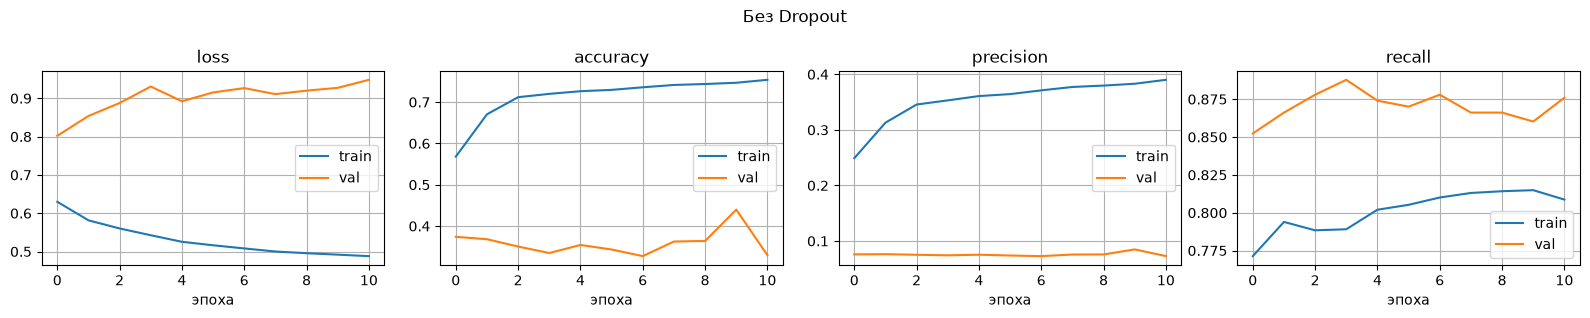

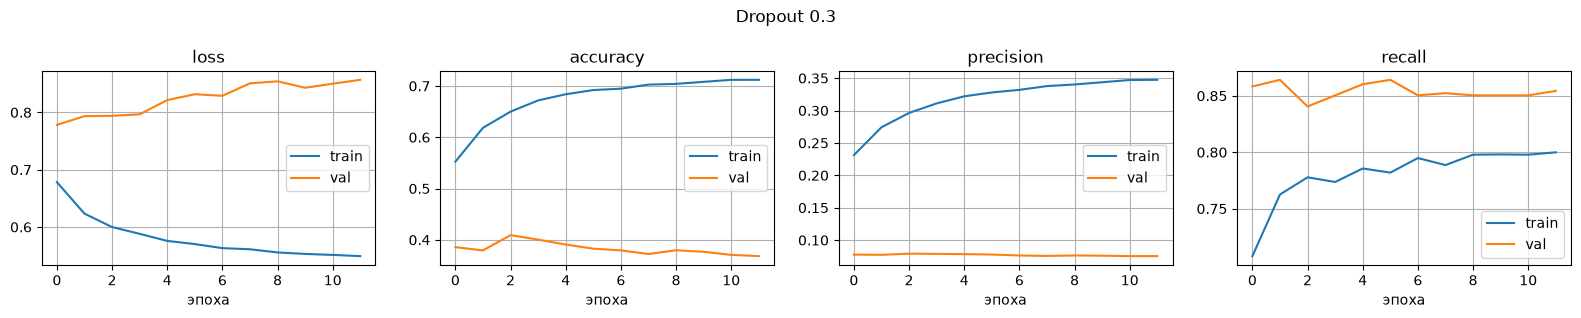

In [13]:
def plot_history(h, title):
    keys = [("loss", "val_loss"), ("accuracy", "val_accuracy"), ("precision", "val_precision"), ("recall", "val_recall")]
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
    for ax, (k, vk) in zip(axes, keys):
        ax.plot(h.history[k], label="train"); ax.plot(h.history[vk], label="val")
        ax.set_title(k); ax.set_xlabel("эпоха"); ax.legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(hist_nodrop, "Без Dropout")
plot_history(hist_drop,   "Dropout 0.3")

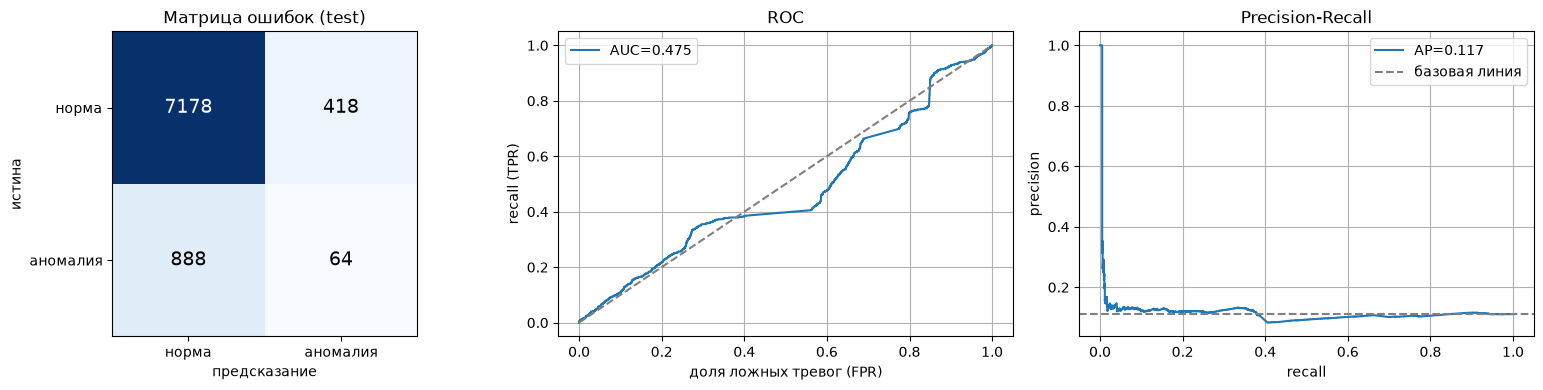

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# матрица ошибок
cm = confusion_matrix(y_te, pred_te)
im = ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks([0, 1], ["норма", "аномалия"]); ax[0].set_yticks([0, 1], ["норма", "аномалия"])
ax[0].set_xlabel("предсказание"); ax[0].set_ylabel("истина"); ax[0].set_title("Матрица ошибок (test)")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
ax[0].grid(False)

# ROC
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[1].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_te, p_te):.3f}"); ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].set_xlabel("доля ложных тревог (FPR)"); ax[1].set_ylabel("recall (TPR)"); ax[1].set_title("ROC"); ax[1].legend()

# PR
pr, rc, _ = precision_recall_curve(y_te, p_te)
ax[2].plot(rc, pr, label=f"AP={average_precision_score(y_te, p_te):.3f}")
ax[2].axhline(y_te.mean(), ls="--", c="gray", label="базовая линия")
ax[2].set_xlabel("recall"); ax[2].set_ylabel("precision"); ax[2].set_title("Precision-Recall"); ax[2].legend()
plt.tight_layout(); plt.show()

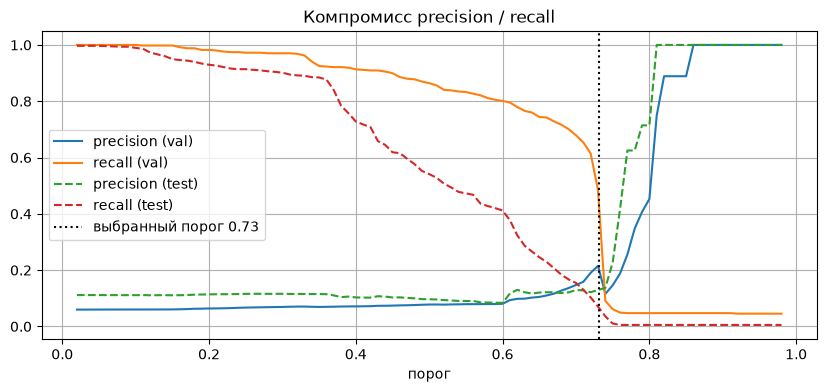

In [15]:
# precision и recall в зависимости от порога (на валидации и на тесте)
ths = np.linspace(0.02, 0.98, 97)
def curve(y, p):
    P = [precision_score(y, (p >= t).astype(int), zero_division=0) for t in ths]
    R = [recall_score(y, (p >= t).astype(int), zero_division=0) for t in ths]
    return P, R
Pv, Rv = curve(y_va, p_va); Pt, Rt = curve(y_te, p_te)
plt.plot(ths, Pv, label="precision (val)"); plt.plot(ths, Rv, label="recall (val)")
plt.plot(ths, Pt, "--", label="precision (test)"); plt.plot(ths, Rt, "--", label="recall (test)")
plt.axvline(THR, c="k", ls=":", label=f"выбранный порог {THR:.2f}")
plt.xlabel("порог"); plt.title("Компромисс precision / recall"); plt.legend(); plt.show()

**Вывод по графикам:** кривые обучения показывают небольшое преимущество Dropout на валидации; ROC-AUC 0,475 близок к случайному ранжированию. Смена порога с 0,5 на 0,732 повышает precision (0,097 → 0,133), но резко снижает recall (0,541 → 0,067). Графики и их интерпретация отражены в README.

---
## 10. Разбор ошибок
**Ответственная: Шмидт**.

### Что нужно сделать
1. Разобрать, где и почему модель ошибается (FP — ложные тревоги, FN — пропуски).
2. Оценить обнаружение на уровне **событий** (аномальных участков), а не отдельных окон.
3. Сформулировать гипотезы и предложить улучшения.

### Теория
Метрики говорят «сколько», разбор ошибок — «почему». Типичные причины:
* **FN (пропуски):** аномалия слабая (малое отклонение), короткая, либо похожа на норму по выбранным признакам.
* **FP (ложные тревоги):** окно нормальное, но необычное (редкий режим работы спутника, всплеск командных каналов).
* **Границы участков:** окно захватывает несколько точек аномалии на краю — метка 1, но признаки почти как у нормы.

**Событийная полнота (event recall)**: аномальный участок считаем найденным, если хотя бы в одном его окне сработала тревога.
Для оператора это важнее, чем «покрытие каждого окна».

In [16]:
y_true, y_pred = y_te, pred_te
err = np.where((y_true == 1) & (y_pred == 0), "FN",
      np.where((y_true == 0) & (y_pred == 1), "FP",
      np.where(y_true == 1, "TP", "TN")))
print(pd.Series(err).value_counts().to_string())

# --- событийная полнота
s_, e_ = runs(y_true)
detected = [bool(y_pred[a:b].any()) for a, b in zip(s_, e_)]
ev_len = e_ - s_
print(f"\nАномальных участков в test: {len(s_)}, найдено: {sum(detected)} ({100*np.mean(detected):.0f}%)")
if len(s_):
    print("средняя длина найденных:", round(ev_len[np.array(detected)].mean(), 1) if any(detected) else "-",
          "| пропущенных:", round(ev_len[~np.array(detected)].mean(), 1) if not all(detected) else "-", "окон")

TN    7178
FN     888
FP     418
TP      64

Аномальных участков в test: 19, найдено: 3 (16%)
средняя длина найденных: 115.0 | пропущенных: 37.9 окон


In [17]:
# --- какие каналы отличают пропущенные аномалии (FN) от найденных (TP)?
# берём признаки "mean_*" (первые len(CH_NAMES) столбцов) в стандартизованном виде
nch = len(CH_NAMES)
Xm = X_te[:, :nch]
rows = {}
for lab in ("TP", "FN", "FP", "TN"):
    rows[lab] = Xm[err == lab].mean(0) if (err == lab).any() else np.full(nch, np.nan)
chan_tab = pd.DataFrame(rows, index=CH_NAMES)
chan_tab["|TP-FN|"] = (chan_tab["TP"] - chan_tab["FN"]).abs()
chan_tab["|FP-TN|"] = (chan_tab["FP"] - chan_tab["TN"]).abs()
print("Каналы, сильнее всего отличающие найденные аномалии от пропущенных:")
display(chan_tab.sort_values("|TP-FN|", ascending=False).head(5).round(2))
print("Каналы, из-за которых нормальные окна «похожи на аномалию» (ложные тревоги):")
display(chan_tab.sort_values("|FP-TN|", ascending=False).head(5).round(2))

Каналы, сильнее всего отличающие найденные аномалии от пропущенных:


,TP,FN,FP,TN,|TP-FN|,|FP-TN|
channel_20,0.85,-0.08,-0.08,-0.08,0.93,0.0
channel_15,0.87,-0.04,-0.04,-0.04,0.91,0.0
channel_16,0.87,-0.04,-0.04,-0.04,0.91,0.0
channel_24,0.83,-0.04,-0.04,-0.04,0.87,0.0
channel_23,0.83,-0.04,-0.04,-0.04,0.87,0.0


Каналы, из-за которых нормальные окна «похожи на аномалию» (ложные тревоги):


,TP,FN,FP,TN,|TP-FN|,|FP-TN|
channel_0,0.21,0.71,0.45,0.84,0.50,0.39
channel_21,-0.60,-0.58,-0.72,-0.40,0.02,0.32
channel_22,-0.58,-0.55,-0.70,-0.40,0.02,0.31
channel_3,-0.77,-0.68,-0.74,-0.44,0.09,0.30
channel_1,-0.67,-0.61,-0.70,-0.41,0.06,0.29


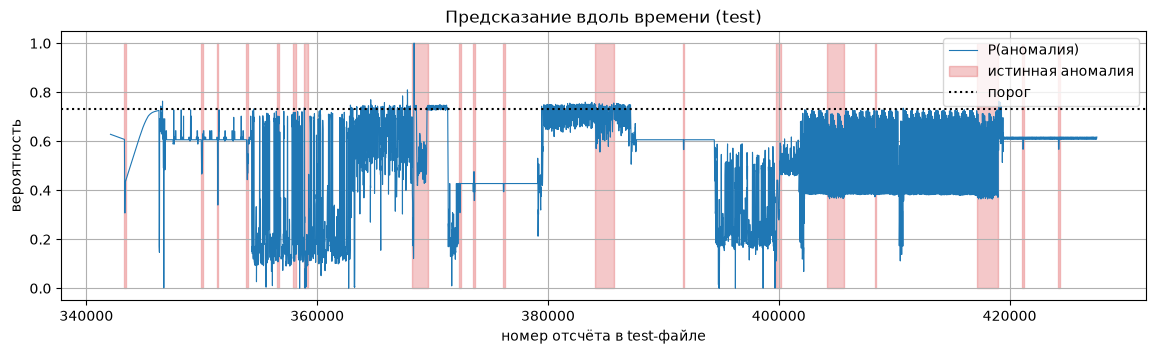

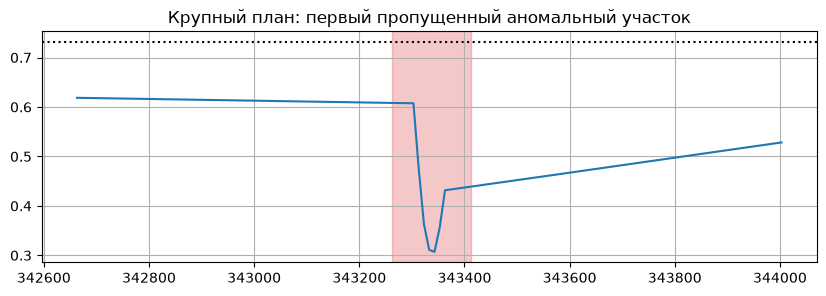

In [18]:
# --- вероятность модели вдоль времени на самом «показательном» участке test
t_axis = data["test"]["starts"]
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(t_axis, p_te, lw=0.8, label="P(аномалия)")
ax.fill_between(t_axis, 0, 1, where=(y_true == 1), color="tab:red", alpha=0.25, label="истинная аномалия")
ax.axhline(THR, c="k", ls=":", label="порог")
ax.set_xlabel("номер отсчёта в test-файле"); ax.set_ylabel("вероятность"); ax.legend(loc="upper right")
ax.set_title("Предсказание вдоль времени (test)"); plt.show()

# крупный план: окрестность первого пропущенного участка (если есть)
missed = [i for i, d in enumerate(detected) if not d]
if missed:
    a, b = s_[missed[0]], e_[missed[0]]
    lo, hi = max(a - 60, 0), min(b + 60, len(p_te))
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(t_axis[lo:hi], p_te[lo:hi]); ax.axhline(THR, c="k", ls=":")
    ax.axvspan(t_axis[a], t_axis[min(b, len(t_axis)-1)], color="tab:red", alpha=0.25)
    ax.set_title("Крупный план: первый пропущенный аномальный участок"); plt.show()
else:
    print("Пропущенных аномальных участков нет.")

### Гипотезы и идеи улучшений
* Добавить признаки: скорость изменения, квантили, число пересечений нуля, спектральные признаки.
* Менять размер окна: короткие аномалии лучше ловятся короткими окнами.
* Подбирать порог не по F1, а по требуемому recall (например, «ловим не менее 90% участков»).
* Попробовать другой подход — модель реконструкции (автокодировщик), обученная только на норме (на train-файле!).
* Собрать больше данных или перебалансировать выборку.

**Вывод по разбору ошибок:** основная проблема — пропуски (888 FN против 64 TP), а событийная полнота составляет 3 из 19 участков. В README зафиксированы предложения проверить окна разной длины, признаки динамики и порог под целевую полноту событий.

---
## 11. README и сдача
**Ответственная: Ерцкина**.

### Что нужно сделать
1. Убедиться, что ноутбук запускается сверху вниз (`Kernel → Restart & Run All`).
2. README дополнен постановкой задачи, описанием данных и лицензии, архитектурой, метриками, выводами и вкладом участниц.
3. Выгрузить в репозиторий ноутбук и файлы датасета (`data/raw/*.tsfile`).

Ячейка ниже собирает сводную таблицу результатов и выводит её на экран (файлы не создаются); таблицу можно скопировать в README. Интерпретация метрик и выводы приведены в README.

In [ ]:
final = report(y_te, p_te, THR)
results = {
    "dataset": "THULab/SMAP (TsFile), CC BY 4.0",
    "task": "бинарная классификация окон телеметрии: 0 = норма, 1 = аномалия",
    "window": WINDOW, "stride": STRIDE, "split_time": SPLIT,
    "n_features": int(X_tr.shape[1]),
    "windows": {k: int(len(v["y"])) for k, v in data.items()},
    "anomaly_share": {k: round(float(v["y"].mean()), 4) for k, v in data.items()},
    "model": best_name, "params": int(model.count_params()),
    "threshold": round(THR, 3),
    "test": {k: round(float(v), 4) for k, v in final.items()},
    "test_roc_auc": round(float(roc_auc_score(y_te, p_te)), 4),
    "test_pr_auc": round(float(average_precision_score(y_te, p_te)), 4),
    "baseline_always_normal": {k: round(float(v), 4) for k, v in baseline.items()},
    "event_recall": round(float(np.mean(detected)), 3) if len(detected) else None,
}
md_text = f"""Результаты

- Модель: **{results['model']}**, параметров: {results['params']}
- Окно {WINDOW}, шаг {STRIDE}, признаков {results['n_features']}; разбиение по времени {SPLIT}
- Порог (по валидации): **{results['threshold']}**

| Метрика (test) | Сеть | Baseline «всегда норма» |
|---|---|---|
| accuracy  | {final['accuracy']:.3f} | {baseline['accuracy']:.3f} |
| precision | {final['precision']:.3f} | {baseline['precision']:.3f} |
| recall    | {final['recall']:.3f} | {baseline['recall']:.3f} |
| F1        | {final['F1']:.3f} | {baseline['F1']:.3f} |

ROC-AUC = {results['test_roc_auc']}, PR-AUC = {results['test_pr_auc']}, событийная полнота = {results['event_recall']}

Данные: SMAP (TsFile), THULab / thuml (Tsinghua University), лицензия CC BY 4.0, https://huggingface.co/datasets/THULab/SMAP
"""
print(md_text)

# Результаты (автоматически из ноутбука)

- Модель: **Dropout 0.3**, параметров: 10177
- Окно 50, шаг 10, признаков 125; разбиение по времени (0.6, 0.2, 0.2)
- Порог (по валидации): **0.732**

| Метрика (test) | Сеть | Baseline «всегда норма» |
|---|---|---|
| accuracy  | 0.847 | 0.889 |
| precision | 0.133 | 0.000 |
| recall    | 0.067 | 0.000 |
| F1        | 0.089 | 0.000 |

ROC-AUC = 0.4749, PR-AUC = 0.1169, событийная полнота = 0.158

Данные: SMAP (TsFile), THULab / thuml (Tsinghua University), лицензия CC BY 4.0, https://huggingface.co/datasets/THULab/SMAP



### Итоговые выводы
1. **Постановка.** Это бинарная классификация: метка 0 означает норму, метка 1 — аномалию. В наборе только две метки.
2. **Recall и precision.** При выбранном на валидации пороге 0.732 recall равен 0.067, precision — 0.133: модель находит около 7 из 100 аномальных окон, и примерно 13 из 100 отмеченных окон действительно аномальны; это около 5,5 ложных тревог на 100 нормальных окон. У baseline «всегда норма» обе метрики равны 0; его accuracy выше (0.889 против 0.847) из-за преобладания нормы. При пороге 0.5 recall выше (0.541), но precision остаётся низким (0.097).
3. **Dropout и class_weight.** На валидации Dropout 0.3 немного улучшил PR-AUC: с 0.158 до 0.189; F1 при пороге 0.5 вырос с 0.139 до 0.143. Class_weight применялся в обоих вариантах, поэтому отдельно оценить его вклад нельзя; на тесте итоговый recall при выбранном пороге низкий.
4. **Причины ошибок.** На тесте 888 FN против 64 TP и 418 FP; найдено 3 из 19 аномальных участков (event recall 0.158). Сравнение признаков выделяет каналы 20, 15, 16, 24 и 23 при различии найденных и пропущенных окон; ложные тревоги отличаются от истинной нормы прежде всего по каналам 0, 21, 22, 3 и 1. Короткие или краевые аномалии и сходство их статистик с нормой могут приводить к пропускам.
5. **Что улучшить.** Сравнить несколько длин окон и добавить признаки динамики/квантилей; выбирать порог под целевой event recall с учётом цены ложных тревог; сравнить классификатор с методом обнаружения аномалий, обученным только на нормальных данных. Сохранять временное разбиение, чтобы не допустить утечки.

**Чек-лист сдачи:**
- [ ] ноутбук проходит `Restart & Run All` без ошибок;
- [ ] в README указаны источник, лицензия CC BY 4.0 и ссылка на статью;
- [x] у каждого раздела подписана ответственная, и её текстовый вывод отражён в README;
- [ ] выводы опираются на числа и графики;
- [ ] папка загружена в репозиторий.

## Глоссарий
| Термин | Простыми словами |
|---|---|
| Признак (feature) | Входное число для модели |
| Метка (label) | Правильный ответ для примера |
| Вес (weight) | Настраиваемое число внутри сети |
| Эпоха | Один проход по всем обучающим данным |
| Batch | Порция примеров за один шаг обучения |
| Loss | Мера ошибки, которую минимизирует обучение |
| Переобучение | Запомнили обучающие данные, на новых плохо |
| Dropout | Случайное выключение нейронов при обучении |
| Порог | Граница вероятности, с которой считаем «аномалия» |
| TP / FP / FN / TN | Верная тревога / ложная тревога / пропуск / верная «норма» |
| Утечка данных | Информация из теста случайно попала в обучение |
| Baseline | Простейший ответ для сравнения («всегда норма») |

## Источники
* Датасет: [THULab/SMAP на Hugging Face](https://huggingface.co/datasets/THULab/SMAP), CC BY 4.0.
* Wu H. и др., *Deep Time Series Models: A Comprehensive Survey and Benchmark*, [arXiv:2407.13278](https://arxiv.org/abs/2407.13278).
* Документация Keras: [Dense](https://keras.io/api/layers/core_layers/dense/), [Dropout](https://keras.io/api/layers/regularization_layers/dropout/), [метрики](https://keras.io/api/metrics/).